In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [4]:
# Create Computer Dataset

data = {
    'age': [
        '<=30', '<=30', '31...40', '>40',
        '>40', '>40', '31...40', '<=30',
        '<=30', '>40', '<=30', '31...40',
        '31...40', '>40'
    ],

    'income': [
        'high', 'high', 'high', 'medium',
        'low', 'low', 'low', 'medium',
        'low', 'medium', 'medium', 'medium',
        'high', 'medium'
    ],

    'student': [
        'no', 'no', 'no', 'no',
        'yes', 'yes', 'yes', 'no',
        'yes', 'yes', 'yes', 'no',
        'yes', 'no'
    ],

    'credit_rating': [
        'fair', 'excellent', 'fair', 'fair',
        'fair', 'excellent', 'excellent', 'fair',
        'fair', 'fair', 'excellent', 'excellent',
        'fair', 'excellent'
    ],

    'buys_computer': [
        'no', 'no', 'yes', 'yes',
        'yes', 'no', 'yes', 'no',
        'yes', 'yes', 'yes', 'yes',
        'yes', 'no'
    ]
}

df = pd.DataFrame(data)

print("Computer Dataset:")
print(df)

print("\nDataset Shape:", df.shape)

Computer Dataset:
        age  income student credit_rating buys_computer
0      <=30    high      no          fair            no
1      <=30    high      no     excellent            no
2   31...40    high      no          fair           yes
3       >40  medium      no          fair           yes
4       >40     low     yes          fair           yes
5       >40     low     yes     excellent            no
6   31...40     low     yes     excellent           yes
7      <=30  medium      no          fair            no
8      <=30     low     yes          fair           yes
9       >40  medium     yes          fair           yes
10     <=30  medium     yes     excellent           yes
11  31...40  medium      no     excellent           yes
12  31...40    high     yes          fair           yes
13      >40  medium      no     excellent            no

Dataset Shape: (14, 5)


In [5]:
# Separate features and target

X = df.drop('buys_computer', axis=1)

y = df['buys_computer']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
       age  income student credit_rating
0     <=30    high      no          fair
1     <=30    high      no     excellent
2  31...40    high      no          fair
3      >40  medium      no          fair
4      >40     low     yes          fair

Target Variable:
0     no
1     no
2    yes
3    yes
4    yes
Name: buys_computer, dtype: object


In [6]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (10, 4)
Testing Data: (4, 4)


In [7]:
# Convert categorical features into numerical format

preprocessor = ColumnTransformer(
    transformers=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'),
         X.columns)
    ]
)

# Create Decision Tree model

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        criterion='entropy',
        random_state=42
    ))
])

# Train the model

model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [8]:
# Predict test data

y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
['yes' 'yes' 'no' 'yes']

Predicted Values:
['yes' 'yes' 'yes' 'yes']


In [9]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 75.0 %


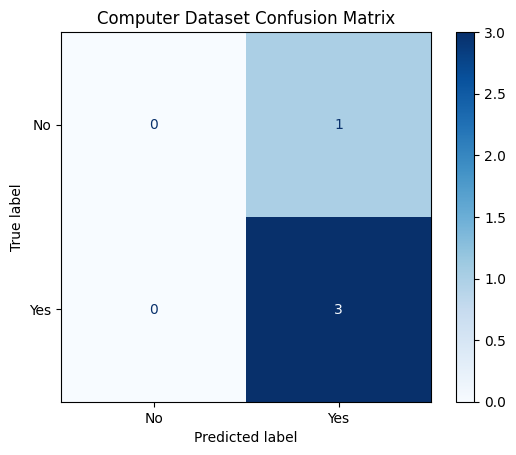

In [10]:
# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['no', 'yes']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')

plt.title("Computer Dataset Confusion Matrix")

plt.show()

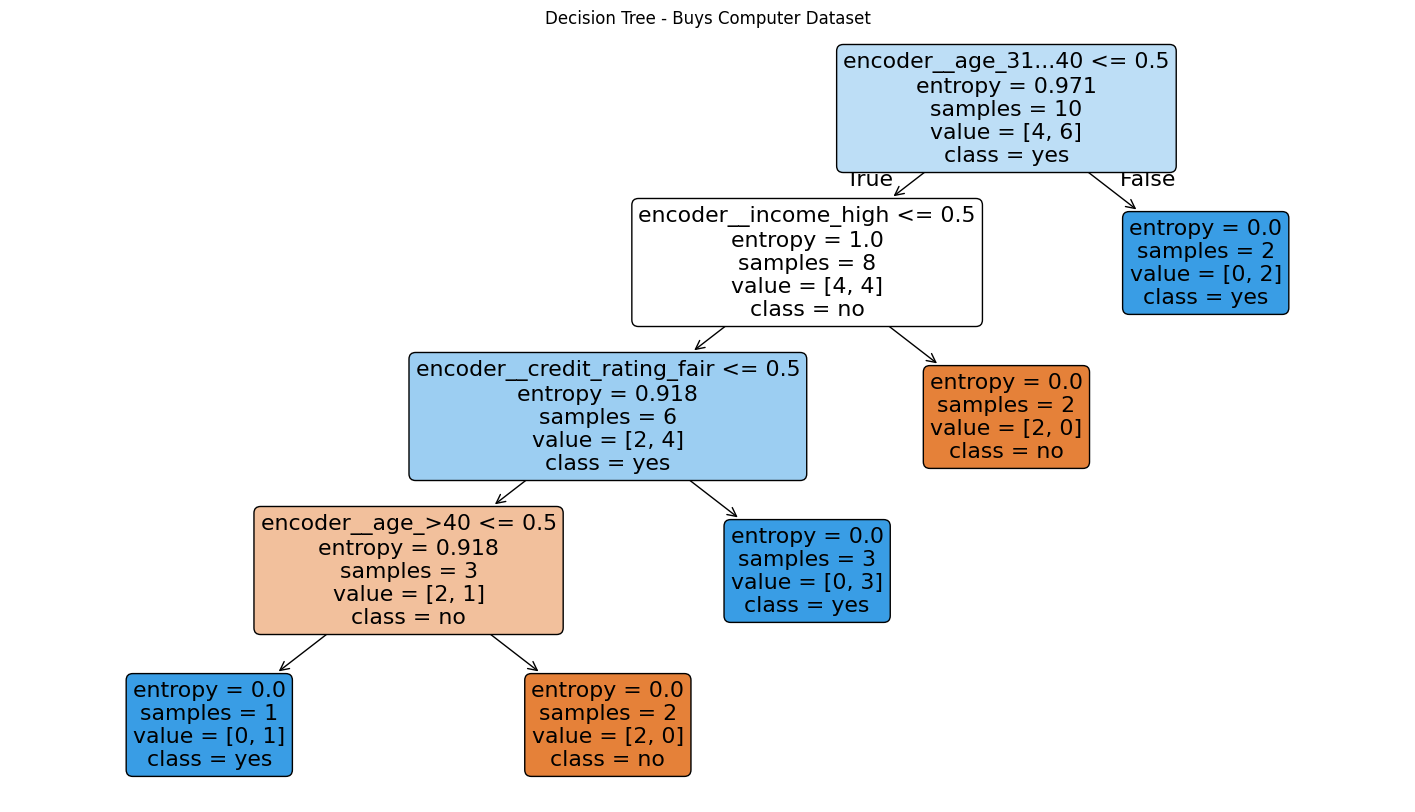

In [11]:
# Visualize Decision Tree

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

tree_model = model.named_steps['classifier']

plt.figure(figsize=(18, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Buys Computer Dataset")

plt.show()

In [12]:
# Predict whether a new person buys a computer

new_person = pd.DataFrame({
    'age': ['<=30'],
    'income': ['medium'],
    'student': ['yes'],
    'credit_rating': ['fair']
})

prediction = model.predict(new_person)

print("Prediction:", prediction[0])

Prediction: yes
